In [25]:
import pandas as pd
import numpy as np
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from igraph import Graph
import os
import numpy
import sys
import pandas as pd
import numpy as np
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
import networkx as nx
import matplotlib.pyplot as plt
from gensim.test.utils import common_texts
from gensim.models import Word2Vec
import torch
from torch.utils.data import Dataset
from transformers import BertModel
import torch.nn as nn
from transformers import Trainer
import torch
import torch_geometric
from torch_geometric.data import Data
import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from torch_geometric.nn import GCNConv, SAGEConv

In [27]:
### PREPARING DATA


# CREATING MATRIX OF WEIGHTS

def get_max_gene_number(df):
    """Find the highest gene number in the dataset."""
    gene_numbers = pd.concat([df['Source'], df['Target']]).str.extract(r'(\d+)').astype(int)
    return gene_numbers.max().values[0]

def create_square_weight_matrix(df, max_gene_num):
    """Create a square weight matrix from gene interactions without extra labels."""
    matrix = np.zeros((max_gene_num, max_gene_num))

    for _, row in df.iterrows():
        source_gene = int(row['Source'][1:]) - 1  # Convert gene names like G1 to index 0
        target_gene = int(row['Target'][1:]) - 1
        matrix[source_gene, target_gene] = row['Weight']

    return matrix

def combine_weight_matrices_simple(data_dir):
    weight_matrices = []
    max_gene_num = 0
    
    # Step 1: Read all the files and find the maximum gene number
    for file in os.listdir(data_dir):
        if file.endswith(".csv"):
            df = pd.read_csv(os.path.join(data_dir, file), header=None, names=["Source", "Target", "Weight"])
            current_max = get_max_gene_number(df)
            max_gene_num = max(max_gene_num, current_max)
    
    # Step 2: Create weight matrices for each algorithm and append them
    for file in os.listdir(data_dir):
        df = pd.read_csv(os.path.join(data_dir, file), header=None, names=["Source", "Target", "Weight"])
        weight_matrix = create_square_weight_matrix(df, max_gene_num)
        weight_matrices.append(weight_matrix)
    
    # Step 3: Combine the matrices side by side
    combined_matrix = np.hstack(weight_matrices)
    
    # Step 4: Label the columns with simple G1, G2, ..., G100 for each algorithm
    column_labels = []
    for i in range(len(weight_matrices)):
        column_labels.extend([f"G{j+1}" for j in range(max_gene_num)])
    
    # Step 5: Label rows as G1, G2, ..., G100
    row_labels = [f"G{i+1}" for i in range(max_gene_num)]
    
    # Create a DataFrame with the proper row and column labels
    combined_df = pd.DataFrame(combined_matrix, index=row_labels, columns=column_labels)
    
    return combined_df

# Example usage
data_dir = "/Users/nirwantandukar/inferred_networks/dream4_100_01_exp/lists/"
combined_df = combine_weight_matrices_simple(data_dir)

# Function to apply NMF with gene names
def apply_nmf_with_gene_names(combined_df, n_components=100):
    # Save the gene names (row names) and column names
    row_gene_names = combined_df.index
    column_gene_names = combined_df.columns

    # Apply NMF
    nmf_model = NMF(n_components=n_components, init='random', random_state=0)
    W = nmf_model.fit_transform(combined_df.values)  # Basis matrix
    H = nmf_model.components_  # Coefficient matrix
    Y = np.dot(W, H)  # Reconstructed matrix

    # Convert W and H back to DataFrames with appropriate labels
    W_df = pd.DataFrame(W, index=row_gene_names, columns=[f"Component_{i+1}" for i in range(n_components)])
    H_df = pd.DataFrame(H, columns=column_gene_names, index=[f"Component_{i+1}" for i in range(n_components)])
    Y_df = pd.DataFrame(Y, index=row_gene_names, columns=column_gene_names)
    
    return Y_df, W_df, H_df

# Example usage
Y_df, W_df, H_df = apply_nmf_with_gene_names(combined_df)


# Threshold the Y matrix to remove low importance values
def threshold_Y_matrix(Y_df, threshold=0.0):
    # Set all values in Y_df below the threshold to 0
    Y_thresholded = Y_df.copy()
    Y_thresholded[Y_thresholded < threshold] = 0
    return Y_thresholded

# Apply thresholding to remove low-value interactions
Y_thresholded = threshold_Y_matrix(Y_df, threshold=0.4)



/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [89]:
Y_thresholded.shape

(100, 1600)

In [287]:
import torch
import torch_geometric
from torch_geometric.nn import GATConv
import torch.nn.functional as F

class MultiAlgorithmGATDeeper(torch.nn.Module):
    def __init__(self, in_channels, out_channels, heads=16, num_edge_features=16):
        super(MultiAlgorithmGATDeeper, self).__init__()
        
        # First GAT layer
        self.gat1 = GATConv(in_channels, out_channels, heads=heads, edge_dim=num_edge_features)
        
        # Second GAT layer
        self.gat2 = GATConv(out_channels * heads, out_channels, heads=heads, edge_dim=num_edge_features)

        # Third GAT layer
        self.gat3 = GATConv(out_channels * heads, out_channels, heads=1, edge_dim=num_edge_features)

    def forward(self, x, edge_index, edge_attr):
        # GAT layer 1
        x, attn_weights_1 = self.gat1(x, edge_index, edge_attr, return_attention_weights=True)
        x = F.elu(x)

        # GAT layer 2
        x, attn_weights_2 = self.gat2(x, edge_index, edge_attr, return_attention_weights=True)
        x = F.elu(x)

        # GAT layer 3
        x, attn_weights_3 = self.gat3(x, edge_index, edge_attr, return_attention_weights=True)

        # Return output and attention weights from all layers
        return x, attn_weights_1, attn_weights_2, attn_weights_3
attn_weights_2


# Initialize the updated GAT model
model = MultiAlgorithmGATDeeper(in_channels=1600, out_channels=1600, heads=16, num_edge_features=16)

# Create dummy input data for 100 genes, 1600 features (16 algorithms, 100 gene interactions each)
x = torch.rand((100, 1600))  # 100 genes, 1600 features (100x16)
edge_index = torch.randint(0, 100, (2, 500))  # Random edges between genes
edge_attr = torch.rand((500, 16))  # 16 features per edge (one per algorithm)

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Training loop
model.train()
for epoch in range(100):  # Adjust epochs as necessary
    optimizer.zero_grad()
    
    # Forward pass
    out, attn_weights_1, attn_weights_2, attn_weights_3 = model(x, edge_index, edge_attr)
    
    # Ensure the output and input sizes match (both should be [100, 1600])
    loss = F.mse_loss(out, x)  # Loss between predicted output and input
    
    # Backpropagation
    loss.backward()
    optimizer.step()
    
    print(f'Epoch {epoch + 1}, Loss: {loss.item()}')

# Now `attn_weights_1`, `attn_weights_2`, and `attn_weights_3` contain attention scores for each edge


Epoch 1, Loss: 0.37630921602249146
Epoch 2, Loss: 59168.01953125
Epoch 3, Loss: 2776020480.0
Epoch 4, Loss: 66095419392.0
Epoch 5, Loss: 2335585536.0
Epoch 6, Loss: 2666614.75
Epoch 7, Loss: 31187924.0
Epoch 8, Loss: 15218.634765625
Epoch 9, Loss: 4291993.0
Epoch 10, Loss: 1810884.0
Epoch 11, Loss: 2570372.0
Epoch 12, Loss: 3231008.5
Epoch 13, Loss: 137514.34375
Epoch 14, Loss: 669664.0625
Epoch 15, Loss: 1101659.5
Epoch 16, Loss: 230130.484375
Epoch 17, Loss: 331693.96875
Epoch 18, Loss: 911527.25
Epoch 19, Loss: 460430.4375
Epoch 20, Loss: 26298.630859375
Epoch 21, Loss: 274758.65625
Epoch 22, Loss: 357906.4375
Epoch 23, Loss: 67972.4296875
Epoch 24, Loss: 99624.0859375
Epoch 25, Loss: 318612.75
Epoch 26, Loss: 202996.609375
Epoch 27, Loss: 13464.3837890625
Epoch 28, Loss: 139979.765625
Epoch 29, Loss: 187486.484375
Epoch 30, Loss: 16766.68359375
Epoch 31, Loss: 112286.3125
Epoch 32, Loss: 124052.3359375
Epoch 33, Loss: 14529.1181640625
Epoch 34, Loss: 40128.08984375
Epoch 35, Loss: 

In [291]:
def combine_attention_weights(attn_weights_1, attn_weights_2, attn_weights_3):
    # Convert attention weights to numpy (optional if they are already in tensor form)
    attn_weights_1 = attn_weights_1[1]  # Assuming we want the attention weights, not the node features
    attn_weights_2 = attn_weights_2[1]
    attn_weights_3 = attn_weights_3[1]

    # Average the attention weights across the three layers
    combined_attn_weights = (attn_weights_1 + attn_weights_2 + attn_weights_3) / 3
    
    return combined_attn_weights

# Example usage
combined_attn_weights = combine_attention_weights(attn_weights_1, attn_weights_2, attn_weights_3)


In [293]:
top_gene_interactions = extract_top_gene_interactions(
    (edge_index, combined_attn_weights), 
    edge_index, 
    gene_names, 
    top_n=50
)

# Print the top interactions
for interaction in top_gene_interactions:
    print(f"Gene Interaction: {interaction[0]} -> {interaction[1]}, Attention: {interaction[2]:.4f}")


IndexError: index 538 is out of bounds for axis 0 with size 500

In [297]:
def extract_top_gene_interactions(attn_weights_tuple, edge_index, gene_names, top_n=20):
    """
    Extract top gene interactions based on attention weights.

    Parameters:
        attn_weights_tuple (Tuple): Tuple containing attention weights and edge index.
        edge_index (Tensor): Edge index matrix (shape [2, num_edges]).
        gene_names (List[str]): List of gene names.
        top_n (int): Number of top interactions to extract.

    Returns:
        List of tuples with (source_gene, target_gene, attention_weight).
    """
    # Unpack the tuple to get the actual attention weights and edge_index
    attn_weights = attn_weights_tuple[1]  # Attention weights (shape: [num_edges, num_heads])
    
    # Ensure we are working with numpy for easier processing
    attn_weights = attn_weights.cpu().detach().numpy()

    # Get source and target node indices for the edges
    source_nodes = edge_index[0].cpu().numpy()
    target_nodes = edge_index[1].cpu().numpy()

    # Ensure attn_weights and edge_index have the same number of edges
    num_edges = min(len(source_nodes), attn_weights.shape[0])
    attn_weights = attn_weights[:num_edges]
    source_nodes = source_nodes[:num_edges]
    target_nodes = target_nodes[:num_edges]

    # Rank the interactions by attention weights
    top_indices = attn_weights.argsort()[-top_n:][::-1]  # Get indices of top N interactions

    # Extract the top interactions
    top_interactions = []
    for idx in top_indices:
        source_gene = gene_names[int(source_nodes[idx])]
        target_gene = gene_names[int(target_nodes[idx])]
        weight = attn_weights[idx]
        top_interactions.append((source_gene, target_gene, weight))

    return top_interactions


In [299]:
# Example gene names for 100 genes
gene_names = [f"G{i+1}" for i in range(100)]

# Extract top interactions after combining attention weights
top_gene_interactions = extract_top_gene_interactions(
    (edge_index, combined_attn_weights), 
    edge_index, 
    gene_names, 
    top_n=50
)

# Print the top interactions
for interaction in top_gene_interactions:
    print(f"Gene Interaction: {interaction[0]} -> {interaction[1]}, Attention: {interaction[2]:.4f}")


TypeError: only length-1 arrays can be converted to Python scalars

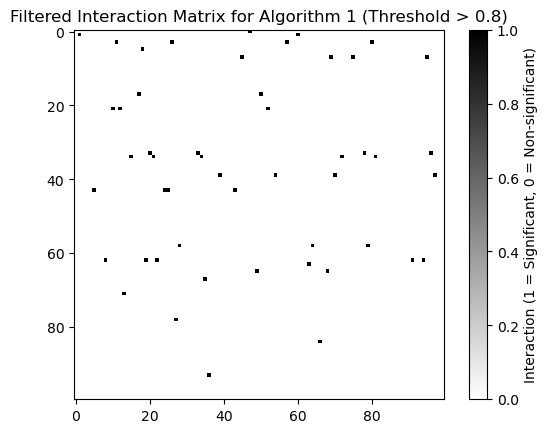

In [273]:
import numpy as np

def create_filtered_matrices(top_gene_interactions_by_algo, gene_names, threshold=0.8, num_genes=100):
    """
    Create a 100x100 matrix for each algorithm with filtered values. 
    If an attention weight is greater than the threshold, mark the corresponding gene pair as 1, else mark it as 0.

    Args:
        top_gene_interactions_by_algo (dict): Dictionary where keys are algorithm indices and values are top interactions.
        gene_names (list): List of gene names corresponding to the nodes.
        threshold (float): Threshold for filtering the attention weights.
        num_genes (int): The number of genes (for creating 100x100 matrices).

    Returns:
        filtered_matrices (dict): Dictionary with algorithm indices as keys and 100x100 matrices as values.
    """
    gene_to_idx = {gene: idx for idx, gene in enumerate(gene_names)}  # Create a mapping from gene name to index
    
    filtered_matrices = {}
    
    # Loop through each algorithm's interactions
    for algo, interactions in top_gene_interactions_by_algo.items():
        # Initialize a 100x100 matrix with zeros
        matrix = np.zeros((num_genes, num_genes))
        
        # Iterate through the interactions for this algorithm
        for interaction in interactions:
            source_gene, target_gene, weight = interaction
            
            # If the attention weight is greater than the threshold, mark it as 1 in the matrix
            if weight > threshold:
                source_idx = gene_to_idx[source_gene]  # Get the index of the source gene
                target_idx = gene_to_idx[target_gene]  # Get the index of the target gene
                matrix[source_idx, target_idx] = 1  # Set 1 for significant interactions
            
        # Store the filtered matrix for this algorithm
        filtered_matrices[algo] = matrix
    
    return filtered_matrices

# Create the filtered 100x100 matrices for each algorithm
filtered_matrices = create_filtered_matrices(top_gene_interactions_by_algo, gene_names, threshold=0.8, num_genes=100)

# Display one of the filtered matrices (for example, for algorithm 1)
import matplotlib.pyplot as plt

plt.imshow(filtered_matrices[0], cmap='binary', interpolation='none')
plt.title("Filtered Interaction Matrix for Algorithm 1 (Threshold > 0.8)")
plt.colorbar(label="Interaction (1 = Significant, 0 = Non-significant)")
plt.show()


In [275]:
filtered_matrices

{0: array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 1., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 1: array([[1., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 2: array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 3: array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.,

In [277]:
import numpy as np

# Assuming filtered_matrices is your dictionary containing matrices from 0 to 15
num_algorithms = 16

# Initialize an empty matrix to store the sum (assuming 100x100 matrices)
summed_matrix = np.zeros_like(filtered_matrices[0])

# Loop through each matrix in filtered_matrices and add them
for i in range(num_algorithms):
    summed_matrix += filtered_matrices[i]

# Print or display the resulting summed matrix
print("Summed Matrix:")
print(summed_matrix)

summed_matrix.shape

Summed Matrix:
[[2. 0. 0. ... 0. 0. 0.]
 [0. 5. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 2.]]


(100, 100)

In [279]:
# Threshold for interaction
threshold = 2

# List to store the interactions
gene_interactions = []

# Loop through the summed matrix and extract interactions greater than or equal to the threshold
for i in range(summed_matrix.shape[0]):  # Loop over rows (genes)
    for j in range(summed_matrix.shape[1]):  # Loop over columns (genes)
        if summed_matrix[i, j] >= threshold:  # Check if the interaction is greater than or equal to the threshold
            gene_interactions.append((f"G{i+1}-G{j+1}", int(summed_matrix[i, j])))

# Print the gene interactions
for interaction in gene_interactions:
    print(f"{interaction[0]} {interaction[1]}")


G1-G1 2
G1-G34 4
G1-G48 5
G2-G2 5
G2-G56 2
G2-G61 9
G2-G87 4
G2-G90 7
G4-G4 5
G4-G12 7
G4-G15 3
G4-G27 11
G4-G56 2
G4-G58 6
G4-G81 8
G4-G91 2
G6-G6 2
G6-G19 3
G8-G1 6
G8-G8 7
G8-G42 5
G8-G54 2
G8-G57 2
G8-G70 10
G8-G76 9
G8-G91 3
G8-G96 9
G8-G100 5
G11-G64 3
G16-G5 2
G18-G10 6
G18-G18 6
G18-G29 7
G18-G45 5
G18-G51 7
G18-G56 4
G18-G69 4
G18-G85 3
G20-G7 2
G22-G11 6
G22-G13 10
G22-G22 7
G22-G23 2
G22-G25 7
G22-G39 5
G22-G47 5
G22-G53 7
G22-G55 7
G26-G26 2
G28-G28 3
G28-G48 2
G28-G88 2
G30-G28 2
G34-G21 8
G34-G34 10
G34-G38 5
G34-G72 3
G34-G79 6
G34-G97 5
G35-G16 3
G35-G22 3
G35-G35 2
G35-G73 3
G35-G82 4
G35-G90 2
G36-G35 3
G36-G36 4
G36-G84 9
G36-G91 2
G37-G62 2
G39-G14 3
G39-G19 2
G39-G66 2
G39-G68 2
G39-G73 4
G40-G4 4
G40-G40 6
G40-G55 5
G40-G71 10
G40-G98 4
G43-G24 5
G43-G43 6
G43-G55 2
G43-G68 2
G43-G99 2
G44-G6 5
G44-G25 2
G44-G26 4
G44-G41 7
G44-G44 15
G50-G12 2
G50-G50 2
G50-G74 2
G52-G42 2
G52-G52 3
G52-G57 2
G52-G59 5
G52-G81 2
G53-G8 2
G55-G16 4
G55-G22 2
G55-G58 2
G55-G86 2
G5

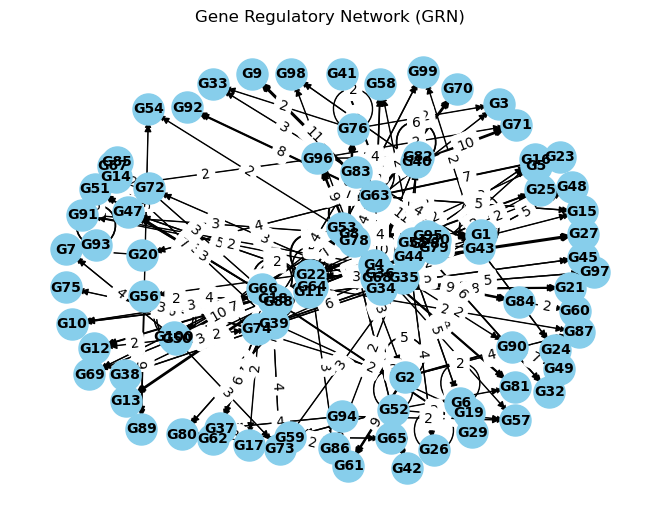

In [281]:
import networkx as nx
import matplotlib.pyplot as plt

def create_grn(gene_interactions):
    """
    Create a GRN from gene interactions.
    
    Parameters:
        gene_interactions (List[Tuple[str, int]]): List of tuples containing gene interactions and their counts.
    
    Returns:
        GRN (networkx.DiGraph): A directed graph representing the gene regulatory network.
    """
    GRN = nx.DiGraph()  # Directed graph for regulatory interactions

    # Add edges to the graph with interaction counts as weights
    for interaction, count in gene_interactions:
        source_gene, target_gene = interaction.split('-')
        GRN.add_edge(source_gene, target_gene, weight=count)
    
    return GRN

def visualize_grn(grn):
    """
    Visualize the GRN using NetworkX and Matplotlib.
    
    Parameters:
        grn (networkx.DiGraph): The gene regulatory network to visualize.
    """
    pos = nx.spring_layout(grn)  # Layout for the graph
    edge_weights = nx.get_edge_attributes(grn, 'weight')

    # Draw the nodes
    nx.draw(grn, pos, with_labels=True, node_color='skyblue', node_size=500, font_size=10, font_weight='bold')
    
    # Draw the edges with varying thickness based on weight
    nx.draw_networkx_edges(grn, pos, width=[0.2 * w for w in edge_weights.values()])
    
    # Draw the edge labels (weights)
    nx.draw_networkx_edge_labels(grn, pos, edge_labels={k: f'{v}' for k, v in edge_weights.items()})

    plt.title("Gene Regulatory Network (GRN)")
    plt.show()

# Create the GRN from the extracted gene interactions
grn = create_grn(gene_interactions)

# Visualize the GRN
visualize_grn(grn)


In [283]:
import pandas as pd
import networkx as nx

# Step 1: Load known (ground truth) interactions
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_05_gs.csv"
ground_truth = pd.read_csv(file_path, index_col=0)

# Convert ground truth matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges

# Get the ground truth edges
known_edges = convert_matrix_to_edge_list(ground_truth)

# Step 2: Get the predicted edges from the GRN (from your constructed GRN)
# Assume GRN is stored in a NetworkX graph `predicted_grn`
predicted_grn=grn
# Convert predicted GRN to edge list
predicted_edges = list(predicted_grn.edges())

# Step 3: Compare the predicted and ground truth edges

# Convert edges to sets for easy comparison
known_edges_set = set(known_edges)
predicted_edges_set = set(predicted_edges)

# True Positives (correct predictions)
true_positives = predicted_edges_set.intersection(known_edges_set)

# False Positives (predicted edges that are not in the ground truth)
false_positives = predicted_edges_set.difference(known_edges_set)

# False Negatives (ground truth edges that are missing in the predictions)
false_negatives = known_edges_set.difference(predicted_edges_set)

# Step 4: Output the results
print(f"Number of True Positives (Correct edges): {len(true_positives)}")
print(f"Number of False Positives (Wrong edges): {len(false_positives)}")
print(f"Number of False Negatives (Missing edges): {len(false_negatives)}")

# Optional: print out the edges for further analysis
print(f"\nTrue Positive Edges:\n{true_positives}")
print(f"\nFalse Positive Edges:\n{false_positives}")
print(f"\nFalse Negative Edges:\n{false_negatives}")


Number of True Positives (Correct edges): 3
Number of False Positives (Wrong edges): 159
Number of False Negatives (Missing edges): 172

True Positive Edges:
{('G63', 'G20'), ('G37', 'G62'), ('G63', 'G78')}

False Positive Edges:
{('G43', 'G24'), ('G44', 'G41'), ('G4', 'G27'), ('G4', 'G56'), ('G76', 'G76'), ('G50', 'G74'), ('G35', 'G16'), ('G8', 'G42'), ('G4', 'G4'), ('G83', 'G33'), ('G20', 'G7'), ('G63', 'G9'), ('G83', 'G43'), ('G72', 'G14'), ('G59', 'G65'), ('G64', 'G99'), ('G63', 'G15'), ('G40', 'G71'), ('G44', 'G6'), ('G64', 'G80'), ('G100', 'G73'), ('G74', 'G37'), ('G88', 'G38'), ('G22', 'G23'), ('G8', 'G96'), ('G96', 'G71'), ('G8', 'G1'), ('G36', 'G36'), ('G34', 'G34'), ('G4', 'G58'), ('G30', 'G28'), ('G22', 'G11'), ('G78', 'G98'), ('G2', 'G56'), ('G76', 'G33'), ('G35', 'G35'), ('G18', 'G18'), ('G8', 'G8'), ('G50', 'G50'), ('G36', 'G84'), ('G35', 'G82'), ('G28', 'G88'), ('G90', 'G49'), ('G18', 'G69'), ('G40', 'G4'), ('G59', 'G80'), ('G34', 'G79'), ('G88', 'G47'), ('G76', 'G3'), (

In [303]:
import geneci
import pandas as pd
import numpy as np

ModuleNotFoundError: No module named 'geneci'